# Phase 1 checks

Visual and tabular sanity checks of `data/processed/`. **No analysis** - only confirms that
the preprocessing produced sensible frames.

* Plots use raw-orientation metres (`x_m`, `y_m`, origin at centre, +y up). The blue arrow
  above the pitch shows the direction the **home** team attacks in that period.
* Filled circle = detected player; hollow dashed ring = extrapolated player (SkillCorner
  `is_detected == False`). Metrica has no detection flag: a player with a position is drawn
  as detected. Ball: black dot (hollow = not detected).
* Numbers under markers are jersey numbers.

In [2]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.load import list_matches, load_meta, load_match, get_frame
from src.viz import plot_frame, legend_handles, HOME, AWAY, INK
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
matches = list_matches()
SC = [m for m in matches if not m.startswith("metrica_")]
ME = [m for m in matches if m.startswith("metrica_")]
rng = np.random.default_rng(2026)
print(len(SC), "SkillCorner matches;", len(ME), "Metrica games")

Fontconfig warning: ignoring C.UTF-8: not a valid language tag
Matplotlib is building the font cache; this may take a moment.


20 SkillCorner matches; 3 Metrica games


In [3]:
def random_frames(match_ids, n, rng):
    picks = []
    for m in rng.choice(match_ids, size=n, replace=len(match_ids) < n):
        meta = load_meta(m)
        p = meta["periods"][rng.integers(len(meta["periods"]))]
        while True:
            fid = int(rng.integers(p["start_frame"], p["end_frame"]))
            f = get_frame(m, fid)
            if f[f.object_type == "player"].x_m.notna().sum() >= 10:
                break
        picks.append((str(m), fid))
    return picks

def plot_grid(picks, title):
    fig, axes = plt.subplots(3, 2, figsize=(14, 14))
    axes = axes.ravel()
    for ax, (m, fid) in zip(axes, picks):
        plot_frame(m, fid, ax=ax)
    axes[-1].axis("off")
    axes[-1].legend(handles=legend_handles(), loc="center", frameon=False, fontsize=10,
                    title="Metrica has no detection flag - players with a position are drawn as detected" if "Metrica" in title else None)
    fig.suptitle(title, fontsize=13, color=INK)
    fig.tight_layout()
    return fig

## 5 random frames - SkillCorner

[('2007448', 23711), ('1986691', 50363), ('1925299', 25961), ('2007721', 30658), ('1874553', 4811)]


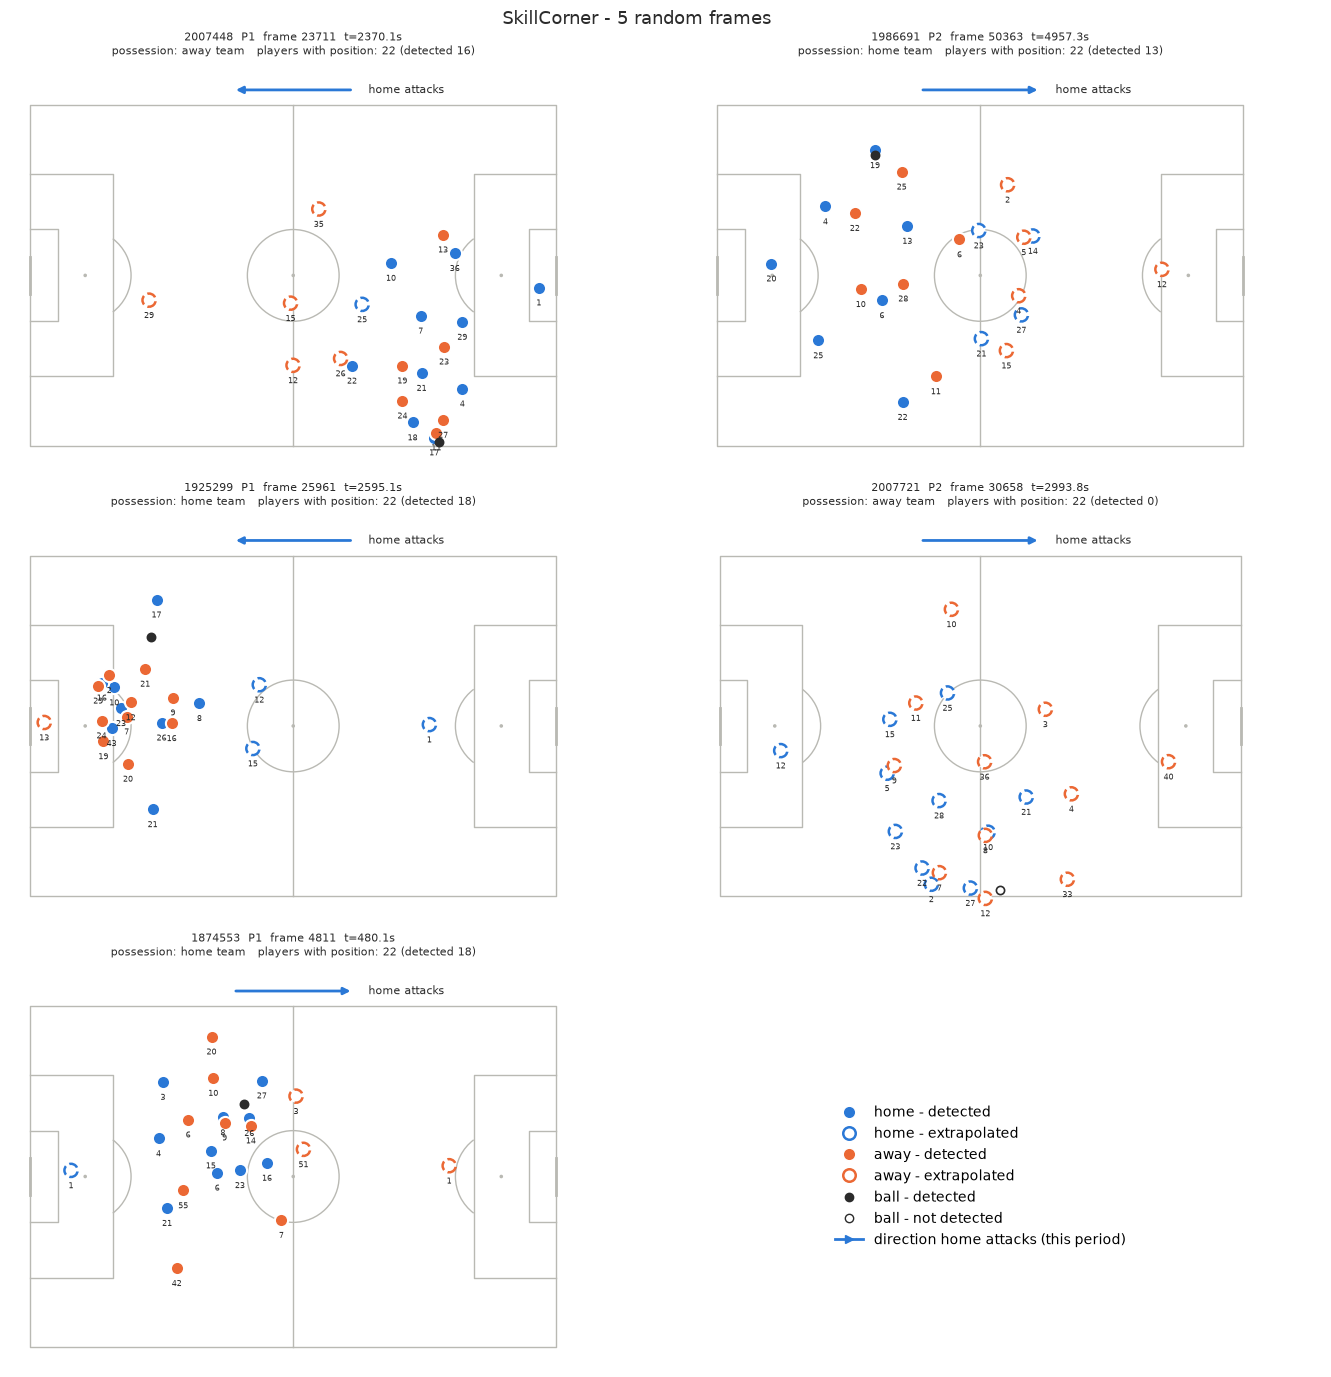

In [3]:
sc_picks = random_frames(SC, 5, rng)
print(sc_picks)
fig = plot_grid(sc_picks, "SkillCorner - 5 random frames")
fig.savefig(ROOT / "notebooks" / "phase1_skillcorner_frames.png", dpi=110)

## 5 random frames - Metrica

[('metrica_game_3', 125438), ('metrica_game_3', 35886), ('metrica_game_3', 130860), ('metrica_game_1', 104331), ('metrica_game_2', 23019)]


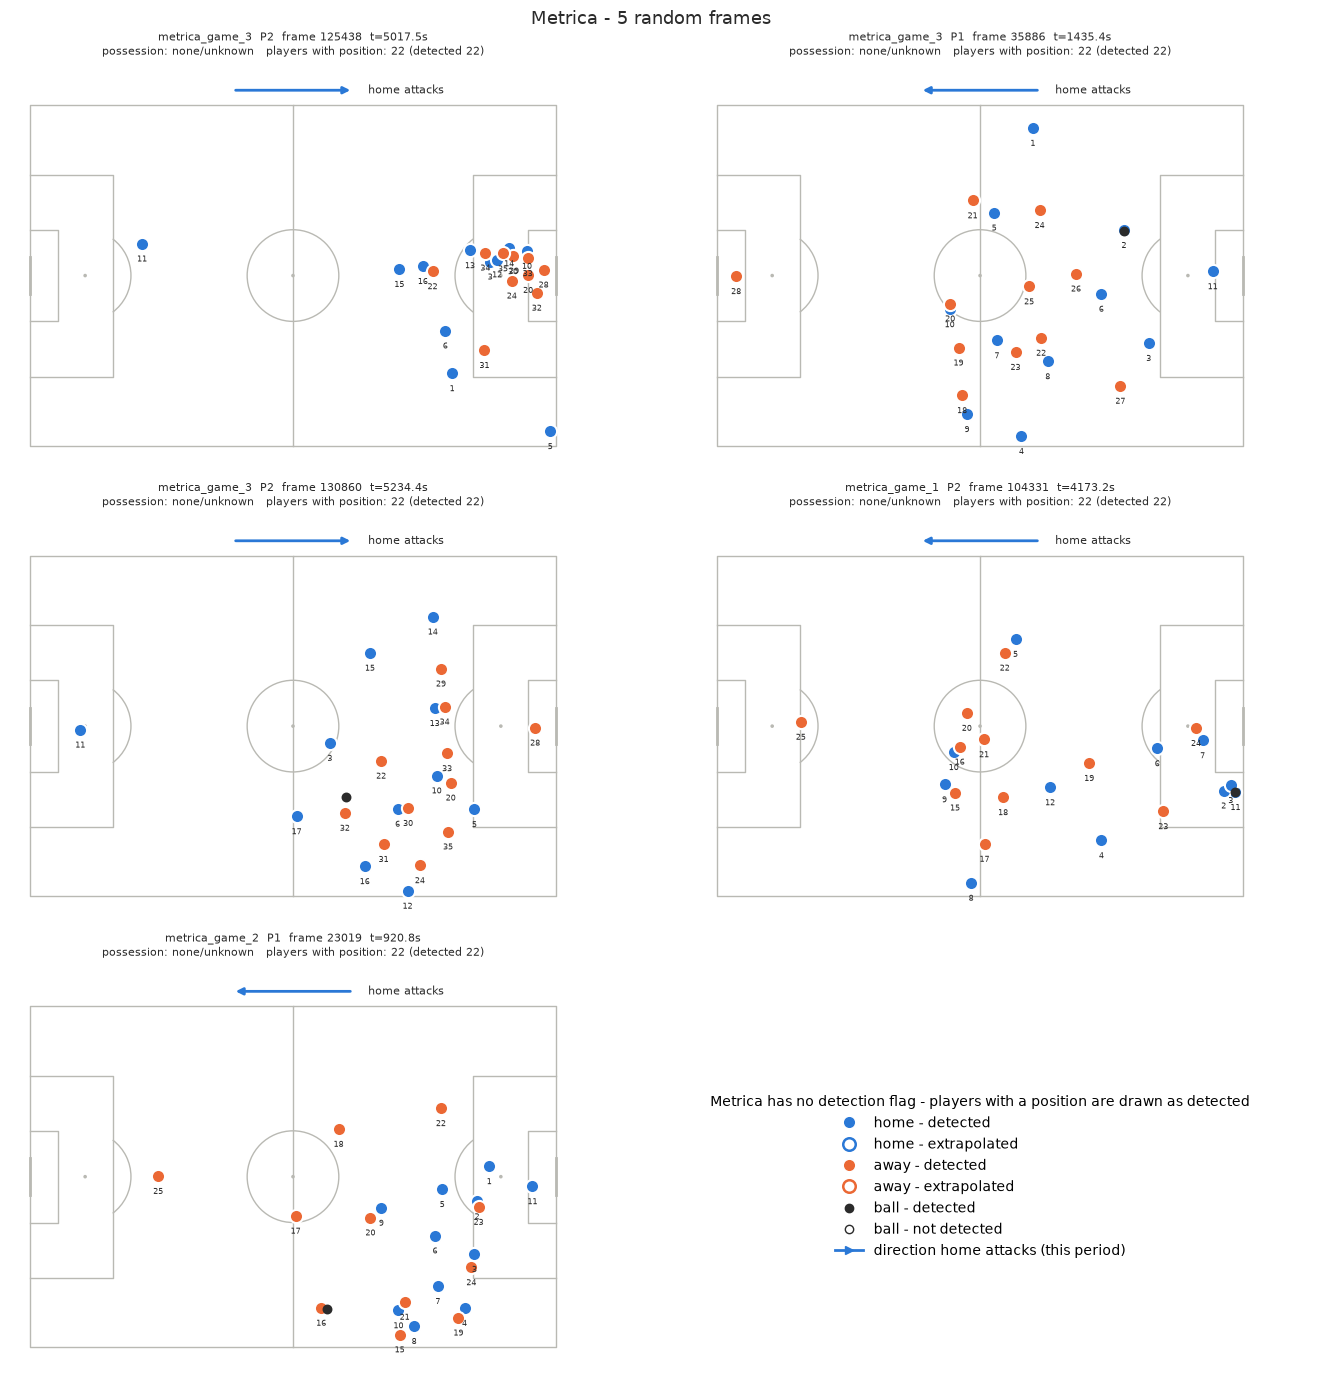

In [4]:
me_picks = random_frames(ME, 5, rng)
print(me_picks)
fig = plot_grid(me_picks, "Metrica - 5 random frames")
fig.savefig(ROOT / "notebooks" / "phase1_metrica_frames.png", dpi=110)

## Share of player-frames detected, per match

* `share_detected_all_rows` = detected player rows / all player rows in the parquet.
* SkillCorner: the file only lists players it tracks at that frame, so this is the true
  detected-vs-extrapolated split.
* Metrica: games 1-2 carry a row for every squad player on every frame (bench = NaN), so the
  all-rows share is diluted by bench rows. `share_detected_on_pitch` restricts to each
  player's on-pitch window (first..last frame with a position, from the metadata lineups).
  Game 3 (EPTS) only lists the 22 active players, so both shares are 100%.

In [5]:
S = {s["match_id"]: s for s in json.loads((ROOT / "data/processed/qa/summary.json").read_text())}
rows = []
for m in matches:
    s = S[m]; meta = load_meta(m)
    r = {"match_id": m, "source": s["source"], "player_rows": s["n_player_rows"],
         "detected_rows": s["player_rows_detected"],
         "share_detected_all_rows": s["share_player_rows_detected"]}
    if s["source"] == "metrica":
        df = load_match(m, columns=["frame_id", "player_id", "is_detected"])
        df = df[df.player_id.notna()]
        win = {l["player_id"]: (l["start_frame"], l["end_frame"]) for l in meta["lineups"] if l["start_frame"] is not None}
        st = df.player_id.map(lambda p: win.get(p, (np.inf, -np.inf))[0])
        en = df.player_id.map(lambda p: win.get(p, (np.inf, -np.inf))[1])
        on = df[(df.frame_id >= st) & (df.frame_id <= en)]
        r["share_detected_on_pitch"] = on.is_detected.mean()
    else:
        r["share_detected_on_pitch"] = r["share_detected_all_rows"]
    rows.append(r)
det_table = pd.DataFrame(rows).set_index("match_id")
det_table.style.format({"share_detected_all_rows": "{:.1%}", "share_detected_on_pitch": "{:.1%}",
                        "player_rows": "{:,}", "detected_rows": "{:,}"})

,source,player_rows,detected_rows,share_detected_all_rows,share_detected_on_pitch
match_id,,,,,
1874553,skillcorner,"973,368","564,001",57.9%,57.9%
1886347,skillcorner,"956,076","566,778",59.3%,59.3%
1899585,skillcorner,"894,982","493,922",55.2%,55.2%
1925299,skillcorner,"1,054,724","610,457",57.9%,57.9%
1927964,skillcorner,"984,698","605,140",61.5%,61.5%
1953632,skillcorner,"966,064","600,059",62.1%,62.1%
1959846,skillcorner,"940,258","536,373",57.0%,57.0%
1986691,skillcorner,"947,672","557,569",58.8%,58.8%
1996435,skillcorner,"957,682","630,145",65.8%,65.8%


## Off-pitch positions x detection flag (per match)

`any` = outside the touch/goal lines; `>2m` = more than 2 m outside (the test margin).
Counts are player rows; ball rows are listed separately.

In [6]:
rows = []
for m in matches:
    s = S[m]
    rows.append({"match_id": m,
        "player_off_detected": s["player_offpitch_any"]["detected"],
        "player_off_extrapolated": s["player_offpitch_any"]["extrapolated_or_absent"],
        "player_off>2m_detected": s["player_offpitch_beyond_margin"]["detected"],
        "player_off>2m_extrapolated": s["player_offpitch_beyond_margin"]["extrapolated_or_absent"],
        "ball_off>2m_detected": s["ball_offpitch_beyond_margin"]["detected"],
        "ball_off>2m_not_detected": s["ball_offpitch_beyond_margin"]["extrapolated_or_absent"],
        "max_abs_x_m": round(s["player_max_abs_x_m"], 1), "max_abs_y_m": round(s["player_max_abs_y_m"], 1)})
off = pd.DataFrame(rows).set_index("match_id")
off

,player_off_detected,player_off_extrapolated,player_off>2m_detected,player_off>2m_extrapolated,ball_off>2m_detected,ball_off>2m_not_detected,max_abs_x_m,max_abs_y_m
match_id,,,,,,,,
1874553,3776,3558,279,870,354,1069,57.2,39.4
1886347,4009,2763,116,606,126,1186,58.3,37.2
1899585,2943,3490,269,833,87,972,57.6,38.0
1925299,3452,2735,115,861,185,1263,57.9,41.0
1927964,2145,3030,172,934,181,960,59.1,39.0
1953632,3958,3650,122,775,103,1258,57.3,39.2
1959846,2548,3711,248,1151,176,1160,58.2,43.0
1986691,3051,3904,316,1162,301,879,56.1,39.9
1996435,3486,2945,295,682,167,1024,58.2,38.6


## Metrica attack-direction checks (games 1-3)

In [7]:
rows = []
for m in ME:
    for k, r in load_meta(m)["direction_checks"].items():
        rows.append({"match_id": m, "period_team": k, "kickoff_frame": r["kickoff_frame"],
                     "a_kickoff": r["a_kickoff_direction"], "a_players_over_halfway(>1m)": r["a_kickoff_wrong_half"],
                     "b_shots": r["b_shots_direction"], "b_n_shots": r["b_shots_n"],
                     "c_deepest": r["c_deepest_direction"], "c_player": r["c_deepest_player"],
                     "c_share": r["c_deepest_share"]})
pd.DataFrame(rows)

,match_id,period_team,kickoff_frame,a_kickoff,a_players_over_halfway(>1m),b_shots,b_n_shots,c_deepest,c_player,c_share
0,metrica_game_1,1_home,1,left_to_right,"{'Player9': 2.83, 'Player10': 5.51}",left_to_right,11,left_to_right,Player11,0.9907
1,metrica_game_1,1_away,1,right_to_left,"{'Player18': 9.68, 'Player19': 4.75, 'Player23...",right_to_left,2,right_to_left,Player25,0.9808
2,metrica_game_1,2_home,72135,right_to_left,{},right_to_left,7,right_to_left,Player11,0.9829
3,metrica_game_1,2_away,72135,left_to_right,{},left_to_right,4,left_to_right,Player25,0.9759
4,metrica_game_2,1_home,51,right_to_left,{},right_to_left,7,right_to_left,Player11,0.9737
5,metrica_game_2,1_away,51,left_to_right,{},left_to_right,4,left_to_right,Player25,0.9872
6,metrica_game_2,2_home,68416,left_to_right,{},left_to_right,6,left_to_right,Player11,0.9733
7,metrica_game_2,2_away,68416,right_to_left,{},right_to_left,7,right_to_left,Player25,0.9857
8,metrica_game_3,1_home,361,right_to_left,{},right_to_left,3,right_to_left,P3578,0.9891
9,metrica_game_3,1_away,361,left_to_right,{},left_to_right,8,left_to_right,P3595,0.9855


In [4]:
import json
MATCH, FRAME, PLAYER = "1874553", 40000, 26766
raw_dir = f"{ROOT}/data/raw/skillcorner_opendata/data/matches/{MATCH}"
with open(f"{raw_dir}/{MATCH}_tracking_extrapolated.jsonl") as f:
    rec = next(json.loads(l) for l in f if l.startswith(f'{{"frame": {FRAME},'))
print("period:", rec["period"], "| timestamp:", rec["timestamp"], "| possession:", rec["possession"])
print("player:", [p for p in rec["player_data"] if p["player_id"] == PLAYER])
m = json.load(open(f"{raw_dir}/{MATCH}_match.json"))
print("pitch:", m["pitch_length"], "x", m["pitch_width"], "| home_team_side:", m["home_team_side"])
pl = next(p for p in m["players"] if p["id"] == PLAYER)
print("team_id:", pl["team_id"], "| home team id:", m["home_team"]["id"], "| number:", pl["number"], "| role:", pl["player_role"]["acronym"])

period: 2 | timestamp: 01:03:20.00 | possession: {'player_id': 809759, 'group': 'away team'}
player: [{'x': -13.02, 'y': -11.74, 'player_id': 26766, 'is_detected': True}]
pitch: 105 x 68 | home_team_side: ['left_to_right', 'right_to_left']
team_id: 866 | home team id: 1802 | number: 3 | role: RCB


In [5]:
import pandas as pd
GAME, MFRAME, MPLAYER = 1, 100000, "Player4"
csv = f"{ROOT}/data/raw/metrica_sample_data/data/Sample_Game_{GAME}/Sample_Game_{GAME}_RawTrackingData_Home_Team.csv"
hdr = pd.read_csv(csv, header=None, nrows=3)
i = hdr.iloc[2].tolist().index(MPLAYER)
raw = pd.read_csv(csv, skiprows=3, header=None)
r = raw[raw[1] == MFRAME].iloc[0]
print("jersey:", hdr.iloc[1, i], "| period:", r[0], "| frame:", r[1], "| time:", r[2], "| raw x:", r[i], "| raw y:", r[i + 1])
print(load_meta(f"metrica_game_{GAME}")["attack_direction"])

jersey: 4 | period: 2.0 | frame: 100000.0 | time: 4000.0 | raw x: 0.29742 | raw y: 0.75638
{'1': {'home': 'left_to_right', 'away': 'right_to_left', 'home_attacks_plus_x': True}, '2': {'home': 'right_to_left', 'away': 'left_to_right', 'home_attacks_plus_x': False}}


In [6]:
cols = ["period","frame_id","timestamp_s","player_id","team_side","jersey_number","position","is_detected",
        "x_raw","y_raw","x_m","y_m","possession_group","x_home_m","y_home_m","x_att_m","y_att_m"]
sc = get_frame(MATCH, FRAME);                    display(sc[sc.player_id == str(PLAYER)][cols].T)
me = get_frame(f"metrica_game_{GAME}", MFRAME);  display(me[me.player_id == MPLAYER][cols].T)

,3
period,2
frame_id,40000
timestamp_s,3800.0
player_id,26766
team_side,away
jersey_number,3
position,RCB
is_detected,True
x_raw,-13.02
y_raw,-11.74


,23
period,2
frame_id,100000
timestamp_s,4000.0
player_id,Player4
team_side,home
jersey_number,4
position,<NA>
is_detected,True
x_raw,0.29742
y_raw,0.75638
